In [1]:
import tabpfn_client
from tabpfn_client import TabPFNClassifier, TabPFNRegressor, set_access_token
from sklearn.model_selection import train_test_split
import pandas as pd
import numpy as np
from tabpfn_extensions.interpretability.shapiq import get_tabpfn_imputation_explainer
from tabpfn_extensions.interpretability.pdp import partial_dependence_plots
import matplotlib
import matplotlib.pyplot as plt
import warnings
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np
warnings.filterwarnings('ignore')




# Authenticate
API_TOKEN = "tabpfn_sk_68PLYl3C5VomK2RapEExGLt4g76XTcf0DKGyXpnPsME"
tabpfn_client.set_access_token(API_TOKEN)

In [2]:
# Load data
df = pd.read_csv(r"C:\Users\Pratham Shah\Downloads\Tubingen\Tabular_Models_Dataset\Updated02\community_index_v9.csv")

print(f"Dataset shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
print("\nTarget (community_suppression) statistics:")
print(df['community_suppression'].describe().round(4))

print("\nRows per diversity level:")
print(df['diversity_level'].value_counts().sort_index())

print("\nRows per community size:")
print(df['community_size'].value_counts().sort_index())

Dataset shape: 48,000 rows × 168 columns

Target (community_suppression) statistics:
count    48000.0000
mean         0.6698
std          0.3767
min          0.0000
25%          0.4471
50%          0.8554
75%          0.9710
max          0.9990
Name: community_suppression, dtype: float64

Rows per diversity level:
diversity_level
1     15000
2     12000
4      9000
8      6000
16     6000
Name: count, dtype: int64

Rows per community size:
community_size
12    9600
16    9600
24    9600
32    9600
48    9600
Name: count, dtype: int64


In [3]:
# feature matrix

r0_cols = [f"R0_c{k}" for k in range(1, 21)]

active_cols = [f"active_c{k}" for k in range(1, 21)]

diversity_col = ['diversity_level']


feature_cols = r0_cols + active_cols + diversity_col

print(f"Feature count:          {len(feature_cols)}  (vs 42 in nutrient+size, 142 in full model)")
print(f"  R0 concentrations:    {len(r0_cols)}")
print(f"  Active flags:         {len(active_cols)}")
print(f"  diversity_level:      {len(diversity_col)}")
print(f"  community_size:       0  ← removed (biological, not chemical)")
print(f"  Species membership:   0  ← removed")

# Diagnostic: confirm all feature columns exist in the loaded file
missing = [c for c in feature_cols if c not in df.columns]
if missing:
    print(f"\nWARNING: {len(missing)} missing columns: {missing}")
else:
    print("\nAll feature columns confirmed present in file.")

X = df[feature_cols]
y = df['community_suppression']

print(f"\nX shape: {X.shape}    y shape: {y.shape}")

Feature count:          41  (vs 42 in nutrient+size, 142 in full model)
  R0 concentrations:    20
  Active flags:         20
  diversity_level:      1
  community_size:       0  ← removed (biological, not chemical)
  Species membership:   0  ← removed

All feature columns confirmed present in file.

X shape: (48000, 41)    y shape: (48000,)


In [4]:
# train test split

strat_col=df['diversity_level']

X_train, X_test, y_train, y_test = train_test_split(X, y, 
                                                    test_size=0.2,
                                                   random_state=42,
                                                   stratify=strat_col
                                                   )

diversity_test=df.loc[X_test.index, 'diversity_level'].values

print(f"\nTrain: {X_train.shape[0]:,} | Test: {X_test.shape[0]:,}")


Train: 38,400 | Test: 9,600


In [5]:
# Train model
model = TabPFNRegressor(
    n_estimators=8,
    random_state=42,
)
model.fit(X_train, y_train)

# Predict
predictions = model.predict(X_test)
mse  = mean_squared_error(y_test, predictions)
rmse = np.sqrt(mse)
mae  = mean_absolute_error(y_test, predictions)
r2   = r2_score(y_test, predictions)


print("TabPFN-3: Overall Test Set Performance")

print(f"  R²   : {r2:.4f}")
print(f"  MAE  : {mae:.4f}")
print(f"  RMSE : {rmse:.4f}")



00:07 Fitting... Done!
00:11 Predicting... Done!
TabPFN-3: Overall Test Set Performance
  R²   : 0.8084
  MAE  : 0.0970
  RMSE : 0.1648


In [6]:
# per diversity level breakdown

print("\nPer-diversity-level performance:")
print(f"{'D':>4} | {'N':>6} | {'R²':>8} | {'MAE':>8} | {'RMSE':>8}")
print("-" * 46)

diversity_levels = sorted(np.unique(diversity_test))

per_d_r2=[]
per_d_mae=[]


for d in diversity_levels:
    mask = (diversity_test == d)
    # Boolean array: True where diversity equals d, False elsewhere.
    # Shape: (n_test,) — same length as y_test and predictions

    y_d    = y_test.values[mask]   # .values converts pandas Series → NumPy array
    pred_d = predictions[mask]     # NumPy fancy indexing: selects elements where mask=True

    if len(y_d) < 5:
        continue  # skip if too few samples to compute meaningful metrics

    d_r2   = r2_score(y_d, pred_d)
    d_mae  = mean_absolute_error(y_d, pred_d)
    d_rmse = np.sqrt(mean_squared_error(y_d, pred_d))

    per_d_r2.append(d_r2)
    per_d_mae.append(d_mae)
    print(f"{int(d):>4} | {len(y_d):>6} | {d_r2:>8.4f} | {d_mae:>8.4f} | {d_rmse:>8.4f}")



Per-diversity-level performance:
   D |      N |       R² |      MAE |     RMSE
----------------------------------------------
   1 |   3000 |   0.8874 |   0.0747 |   0.1500
   2 |   2400 |   0.8053 |   0.0959 |   0.1816
   4 |   1800 |   0.1086 |   0.0929 |   0.1532
   8 |   1200 |   0.3457 |   0.1188 |   0.1697
  16 |   1200 |  -0.0018 |   0.1396 |   0.1766


In [7]:
# ── Per-community-size breakdown ──────────────────────────────────────────────

community_size_test = df.loc[X_test.index, 'community_size'].values
# Same pattern as diversity_test — retrieve the community_size for each
# test sample using its original row label from df

print("\nPer-community-size performance:")
print(f"{'N':>6} | {'n_samples':>10} | {'R²':>8} | {'MAE':>8} | {'RMSE':>8}")
print("-" * 52)

for n in sorted(np.unique(community_size_test)):
    mask = (community_size_test == n)
    y_n    = y_test.values[mask]
    pred_n = predictions[mask]

    if len(y_n) < 5:
        continue

    n_r2   = r2_score(y_n, pred_n)
    n_mae  = mean_absolute_error(y_n, pred_n)
    n_rmse = np.sqrt(mean_squared_error(y_n, pred_n))

    print(f"{int(n):>6} | {len(y_n):>10} | {n_r2:>8.4f} | {n_mae:>8.4f} | {n_rmse:>8.4f}")


Per-community-size performance:
     N |  n_samples |       R² |      MAE |     RMSE
----------------------------------------------------
    12 |       1870 |   0.5623 |   0.1485 |   0.2454
    16 |       1934 |   0.7258 |   0.1113 |   0.1937
    24 |       1920 |   0.8912 |   0.0731 |   0.1213
    32 |       1963 |   0.9093 |   0.0724 |   0.1099
    48 |       1913 |   0.9133 |   0.0817 |   0.1113


Saved: tabpfn_0203_diagnostics.png


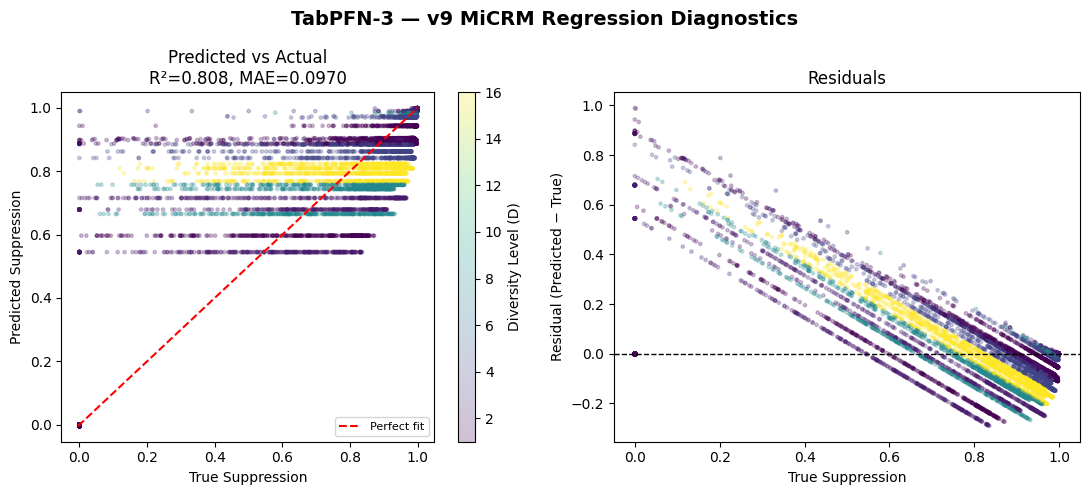

Saved: tabpfn_0203_diversity.png


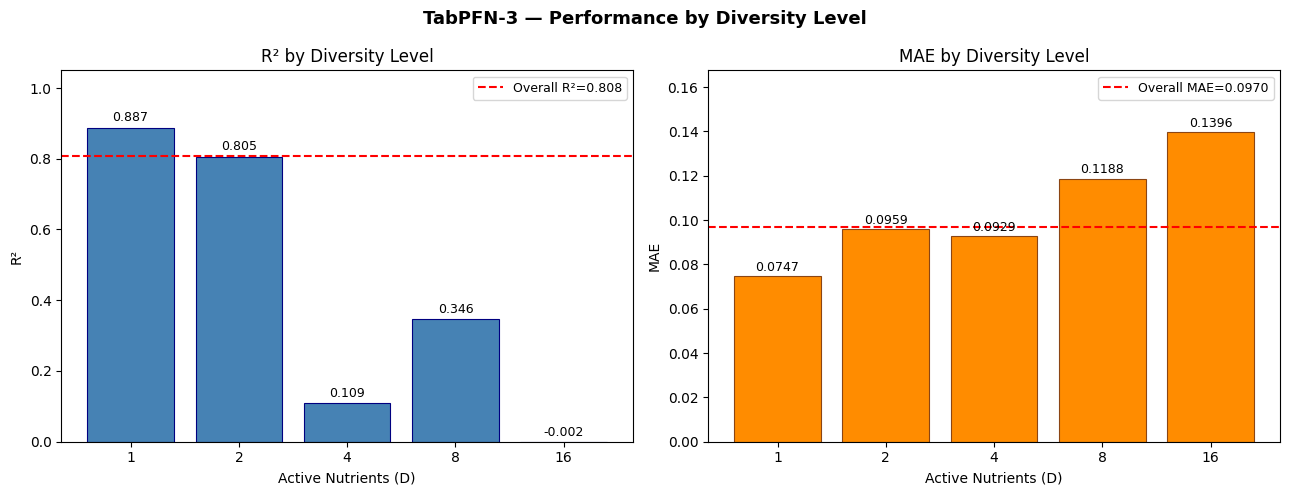

Saved: tabpfn_0203_community_size.png


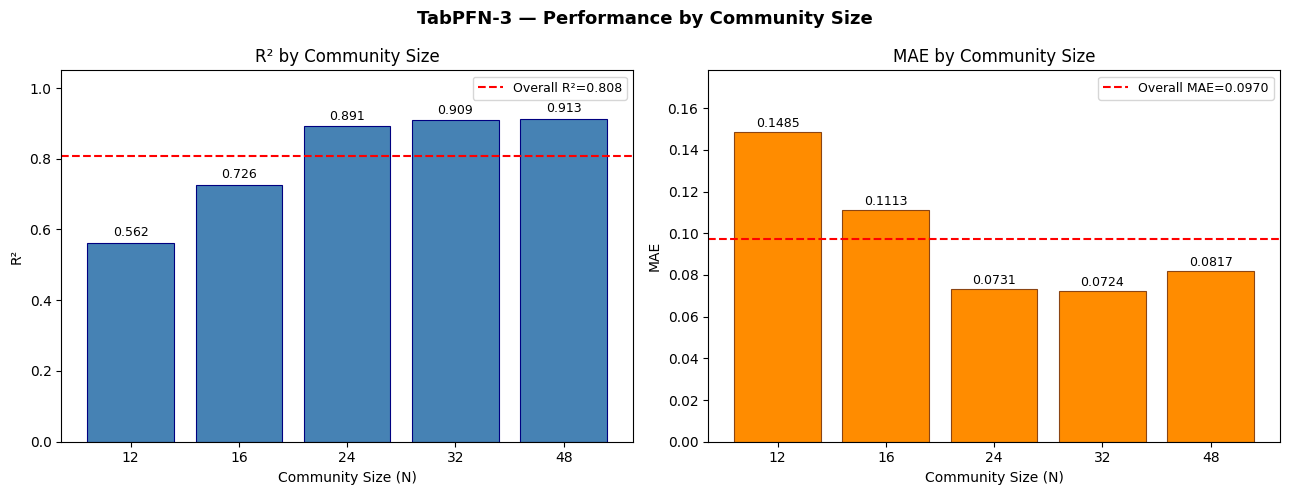

In [8]:
# =============================================================================
# ── DIAGNOSTIC PLOTS ───────────────────────────────────────────────
# =============================================================================

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
fig.suptitle("TabPFN-3 — v9 MiCRM Regression Diagnostics", fontsize=14, fontweight='bold')

# ── Panel 1: Predicted vs. Actual ─────────────────────────────────────────────
ax = axes[0]
sc = ax.scatter(y_test, predictions, alpha=0.25, s=6,
                c=diversity_test, cmap='viridis')
# c=diversity_test: colours each point by its diversity level
# cmap='viridis': maps low D to purple, high D to yellow

plt.colorbar(sc, ax=ax, label='Diversity Level (D)')
# colorbar(): adds a colour bar legend on the side of the plot
# ax=ax: attaches it to this specific subplot

lims = [min(y_test.min(), predictions.min()),
        max(y_test.max(), predictions.max())]
ax.plot(lims, lims, 'r--', lw=1.5, label='Perfect fit')
ax.set_xlabel("True Suppression")
ax.set_ylabel("Predicted Suppression")
ax.set_title(f"Predicted vs Actual\nR²={r2:.3f}, MAE={mae:.4f}")
ax.legend(fontsize=8)

# ── Panel 2: Residuals ────────────────────────────────────────────────────────
ax2 = axes[1]
residuals = predictions - y_test.values
# predictions is a NumPy array; y_test is a pandas Series.
# .values converts y_test to NumPy so subtraction is element-wise.

ax2.scatter(y_test, residuals, alpha=0.25, s=6,
            c=diversity_test, cmap='viridis')
ax2.axhline(0, color='black', lw=1, ls='--')
# axhline(0): horizontal reference line at zero error.
# Residuals scattered symmetrically around this = well-calibrated model.
ax2.set_xlabel("True Suppression")
ax2.set_ylabel("Residual (Predicted − True)")
ax2.set_title("Residuals")

plt.tight_layout()
plt.savefig("tabpfn_0203_diagnostics.png", dpi=150, bbox_inches='tight')
print("Saved: tabpfn_0203_diagnostics.png")
plt.show()

# =============================================================================
# ── SECTION 9: PER-DIVERSITY-LEVEL PLOTS ──────────────────────────────────────
# =============================================================================

diversity_levels = sorted(np.unique(diversity_test))
per_d_r2  = []
per_d_mae = []

for d in diversity_levels:
    mask   = (diversity_test == d)
    y_d    = y_test.values[mask]
    pred_d = predictions[mask]
    if len(y_d) < 5:
        per_d_r2.append(np.nan)
        per_d_mae.append(np.nan)
        continue
    per_d_r2.append(r2_score(y_d, pred_d))
    per_d_mae.append(mean_absolute_error(y_d, pred_d))

fig2, axes2 = plt.subplots(1, 2, figsize=(13, 5))
fig2.suptitle("TabPFN-3 — Performance by Diversity Level", fontsize=13, fontweight='bold')

d_labels = [str(int(d)) for d in diversity_levels]
# Converts diversity level integers to strings for x-axis tick labels

# ── Left: R² by diversity level ───────────────────────────────────────────────
ax_d_r2 = axes2[0]
bars_d_r2 = ax_d_r2.bar(d_labels, per_d_r2,
                          color='steelblue', edgecolor='navy', linewidth=0.8)
ax_d_r2.axhline(r2, color='red', ls='--', lw=1.5, label=f'Overall R²={r2:.3f}')
# Red dashed line at overall R² — shows which D levels pull performance up or down
ax_d_r2.set_xlabel("Active Nutrients (D)")
ax_d_r2.set_ylabel("R²")
ax_d_r2.set_title("R² by Diversity Level")
ax_d_r2.set_ylim(0, 1.05)
ax_d_r2.legend(fontsize=9)

for bar, val in zip(bars_d_r2, per_d_r2):
    if not np.isnan(val):
        ax_d_r2.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.01,
            f"{val:.3f}",
            ha='center', va='bottom', fontsize=9
        )

# ── Right: MAE by diversity level ─────────────────────────────────────────────
ax_d_mae = axes2[1]
bars_d_mae = ax_d_mae.bar(d_labels, per_d_mae,
                            color='darkorange', edgecolor='saddlebrown', linewidth=0.8)
ax_d_mae.axhline(mae, color='red', ls='--', lw=1.5, label=f'Overall MAE={mae:.4f}')
ax_d_mae.set_xlabel("Active Nutrients (D)")
ax_d_mae.set_ylabel("MAE")
ax_d_mae.set_title("MAE by Diversity Level")
ax_d_mae.set_ylim(0, max([v for v in per_d_mae if not np.isnan(v)]) * 1.2)
# max([v for v in per_d_mae if not np.isnan(v)]): finds the largest non-NaN MAE.
# The list comprehension filters out NaN values before taking the max,
# because max() would return NaN if any element is NaN.
# * 1.2 adds 20% headroom so bar annotations don't get clipped.
ax_d_mae.legend(fontsize=9)

for bar, val in zip(bars_d_mae, per_d_mae):
    if not np.isnan(val):
        ax_d_mae.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.001,
            f"{val:.4f}",
            ha='center', va='bottom', fontsize=9
        )

plt.tight_layout()
plt.savefig("tabpfn_0203_diversity.png", dpi=150, bbox_inches='tight')
print("Saved: tabpfn_0203_diversity.png")
plt.show()

# =============================================================================
# ── SECTION 10: PER-COMMUNITY-SIZE PLOTS ──────────────────────────────────────
# =============================================================================

community_size_test = df.loc[X_test.index, 'community_size'].values
# df.loc[X_test.index, 'community_size']: retrieves the community_size value
# for each test sample using its original row label in df.
# X_test.index holds those original labels even after the train/test split.

size_levels  = sorted(np.unique(community_size_test))
per_size_r2  = []
per_size_mae = []

for n in size_levels:
    mask   = (community_size_test == n)
    y_n    = y_test.values[mask]
    pred_n = predictions[mask]
    if len(y_n) < 5:
        per_size_r2.append(np.nan)
        per_size_mae.append(np.nan)
        continue
    per_size_r2.append(r2_score(y_n, pred_n))
    per_size_mae.append(mean_absolute_error(y_n, pred_n))

fig3, axes3 = plt.subplots(1, 2, figsize=(13, 5))
fig3.suptitle("TabPFN-3 — Performance by Community Size", fontsize=13, fontweight='bold')

size_labels = [str(int(n)) for n in size_levels]

# ── Left: R² by community size ────────────────────────────────────────────────
ax_s_r2 = axes3[0]
bars_s_r2 = ax_s_r2.bar(size_labels, per_size_r2,
                          color='steelblue', edgecolor='navy', linewidth=0.8)
ax_s_r2.axhline(r2, color='red', ls='--', lw=1.5, label=f'Overall R²={r2:.3f}')
ax_s_r2.set_xlabel("Community Size (N)")
ax_s_r2.set_ylabel("R²")
ax_s_r2.set_title("R² by Community Size")
ax_s_r2.set_ylim(0, 1.05)
ax_s_r2.legend(fontsize=9)

for bar, val in zip(bars_s_r2, per_size_r2):
    if not np.isnan(val):
        ax_s_r2.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.01,
            f"{val:.3f}",
            ha='center', va='bottom', fontsize=9
        )

# ── Right: MAE by community size ──────────────────────────────────────────────
ax_s_mae = axes3[1]
bars_s_mae = ax_s_mae.bar(size_labels, per_size_mae,
                            color='darkorange', edgecolor='saddlebrown', linewidth=0.8)
ax_s_mae.axhline(mae, color='red', ls='--', lw=1.5, label=f'Overall MAE={mae:.4f}')
ax_s_mae.set_xlabel("Community Size (N)")
ax_s_mae.set_ylabel("MAE")
ax_s_mae.set_title("MAE by Community Size")
ax_s_mae.set_ylim(0, max([v for v in per_size_mae if not np.isnan(v)]) * 1.2)
ax_s_mae.legend(fontsize=9)

for bar, val in zip(bars_s_mae, per_size_mae):
    if not np.isnan(val):
        ax_s_mae.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.001,
            f"{val:.4f}",
            ha='center', va='bottom', fontsize=9
        )

plt.tight_layout()
plt.savefig("tabpfn_0203_community_size.png", dpi=150, bbox_inches='tight')
print("Saved: tabpfn_0203_community_size.png")
plt.show()


Computing SHAP values (cloud API — may take a few minutes)...
00:10 Predicting... Done!


  0%|          | 0/30 [00:00<?, ?it/s]

00:09 Predicting... Done!
00:15 Predicting... Done!
00:09 Predicting... Done!
00:13 Predicting... Done!
00:09 Predicting... Done!
00:13 Predicting... Done!
00:08 Predicting... Done!
00:13 Predicting... Done!
00:09 Predicting... Done!
00:13 Predicting... Done!
00:09 Predicting... Done!
00:13 Predicting... Done!
00:09 Predicting... Done!
00:13 Predicting... Done!
00:09 Predicting... Done!
00:13 Predicting... Done!
00:09 Predicting... Done!
00:13 Predicting... Done!
00:09 Predicting... Done!
00:13 Predicting... Done!
00:10 Predicting... Done!
00:13 Predicting... Done!
00:00 Predicting... \

00:06 Predicting... Done!
00:13 Predicting... Done!
00:10 Predicting... Done!
00:12 Predicting... Done!
00:10 Predicting... Done!
00:13 Predicting... Done!
00:00 Predicting... \

00:06 Predicting... Done!
00:13 Predicting... Done!
00:00 Predicting... \

...

00:06 Predicting... Done!
00:13 Predicting... Done!
00:00 Predicting... \

00:06 Predicting... Done!
00:13 Predicting... Done!
00:00 Predicting... \

00:06 Predicting... Done!
00:13 Predicting... Done!
00:09 Predicting... Done!
00:13 Predicting... Done!
00:09 Predicting... Done!
00:13 Predicting... Done!
00:00 Predicting... \

00:06 Predicting... Done!
00:13 Predicting... Done!
00:00 Predicting... \

00:06 Predicting... Done!
00:13 Predicting... Done!
00:10 Predicting... Done!
00:13 Predicting... Done!
SHAP computation complete.
Saved: tabpfn_shap_bar_0203.png


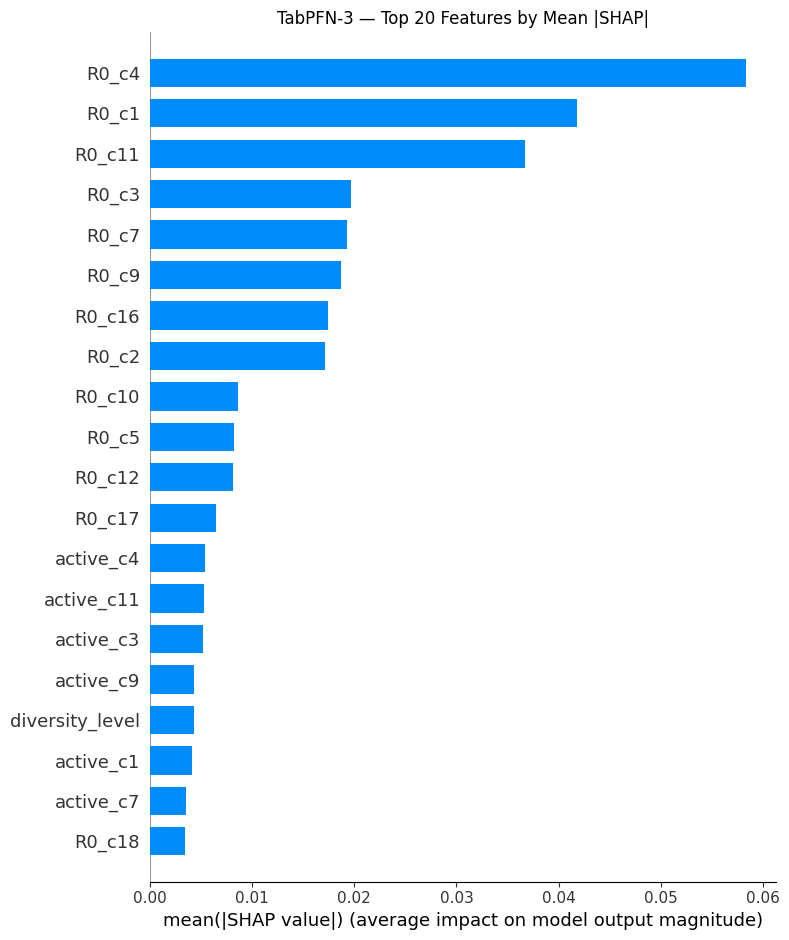

Saved: tabpfn_shap_beeswarm_0203.png


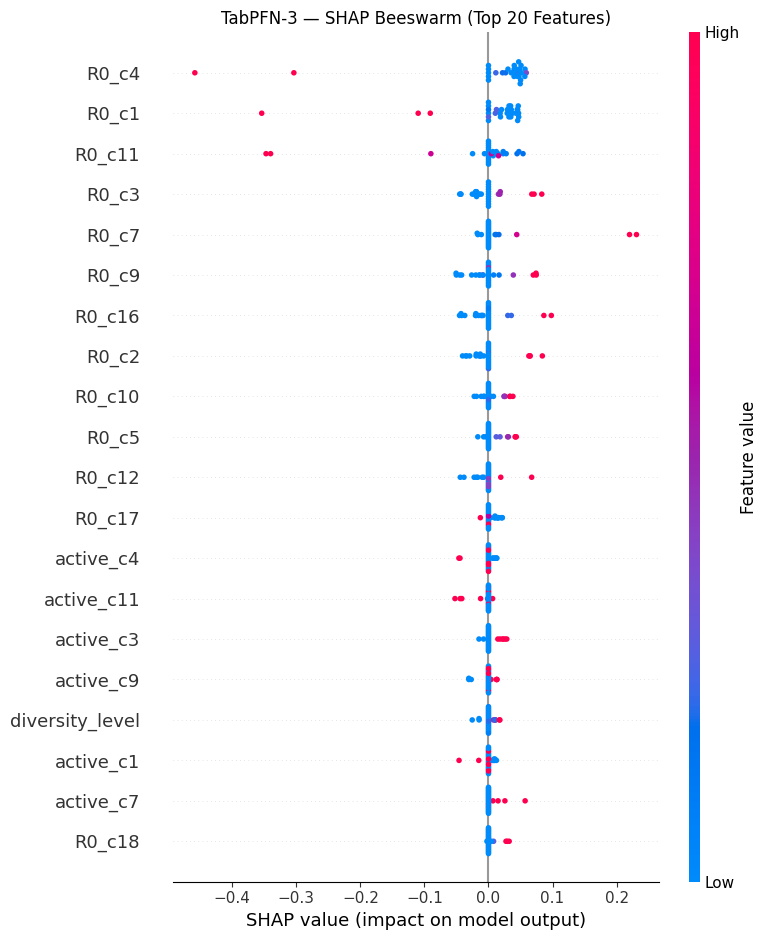

In [9]:
# =============================================================================
# ── SECTION 11: SHAP INTERPRETABILITY (cloud API compatible) ──────────────────
# =============================================================================
# SHAP answers: for each prediction, how much did each feature push the output
# up or down from the baseline (mean prediction)?
# Each SHAP value is a signed number:
#   positive → this feature pushed suppression HIGHER for this sample
#   negative → this feature pushed suppression LOWER for this sample
# The magnitude tells you how much, the sign tells you the direction.

import shap

print("\nComputing SHAP values (cloud API — may take a few minutes)...")

N_EXPLAIN = 30
# Number of test samples to explain.
# Each sample requires many masked .predict() calls to the Prior Labs API.
# Start with 30 to confirm it works, raise to 100 for final results.

feature_names = list(X_test.columns)
# X_test.columns: the column names of the DataFrame.
# list() converts it to a plain Python list for use in pd.DataFrame() later.

# Convert to NumPy BEFORE passing anything to SHAP.
# This prevents SHAP from stripping column names internally,
# which caused the "columns differ" error from the TabPFN API.
X_train_np   = X_train.values
# .values: converts a pandas DataFrame → NumPy array, shape (n_train, n_features).
# Column names are dropped — it becomes a plain numeric matrix.

X_explain_np = X_test.iloc[:N_EXPLAIN].values
# .iloc[:N_EXPLAIN]: select first N_EXPLAIN rows by integer position.
# .values: convert that DataFrame slice to a NumPy array.

background = shap.sample(X_train_np, 100, random_state=42)
# shap.sample(array, n, random_state): randomly picks n rows from the array.
# This background dataset represents the "average" input — when SHAP masks
# out a feature, it replaces it with values drawn from this background.
# 100 rows is standard; enough to represent the distribution, not too slow.

def predict_fn(X):
    # SHAP internally passes NumPy arrays to this function when computing
    # masked predictions. But TabPFN's cloud API checks that column names
    # match what it saw at .fit() time.
    # So we wrap model.predict() to restore column names before each call.
    return model.predict(pd.DataFrame(X, columns=feature_names))
    # pd.DataFrame(X, columns=feature_names):
    #   X       → the NumPy array SHAP constructed with some features masked
    #   columns → restores the original column names so TabPFN recognises them

explainer = shap.KernelExplainer(
    model=predict_fn,
    # We pass our wrapper function, not model.predict directly.
    # KernelExplainer will call predict_fn(masked_X) hundreds of times
    # per sample to estimate each feature's marginal contribution.

    data=background,
    # The background dataset used for marginalisation.
    # When feature j is "removed", its value is replaced by a draw from here.
)

shap_values = explainer.shap_values(
    X_explain_np,
    # The test samples to explain — NumPy array, shape (N_EXPLAIN, n_features).

    nsamples=256,
    # Number of masked coalitions evaluated per sample.
    # Higher → more accurate SHAP values but more API calls → slower.
    # 256 is a good starting point. Raise to 512 for final/report results.
)
# Returns NumPy array of shape (N_EXPLAIN, n_features).
# shap_values[i, j] = SHAP contribution of feature j to sample i's prediction.

print("SHAP computation complete.")

# =============================================================================
# ── SHAP Summary Bar Plot ─────────────────────────────────────────────────────
# Shows mean |SHAP| per feature — global importance across all explained samples.
# =============================================================================

plt.figure()
shap.summary_plot(
    shap_values,
    X_explain_np,
    feature_names=feature_names,
    max_display=20,
    # max_display=20: only show the 20 most important features.
    # With 142 features, showing all would be unreadable.
    show=False,
    # show=False: suppress plt.show() inside shap so we can save first.
    plot_type="bar",
    # plot_type="bar": horizontal bar chart of mean |SHAP| per feature.
)
plt.title("TabPFN-3 — Top 20 Features by Mean |SHAP|")
plt.tight_layout()
plt.savefig("tabpfn_shap_bar_0203.png", dpi=150, bbox_inches='tight')
print("Saved: tabpfn_shap_bar_0203.png")
plt.show()

# =============================================================================
# ── SHAP Beeswarm Plot ────────────────────────────────────────────────────────
# Shows the DISTRIBUTION of SHAP values across all explained samples.
# Each dot is one sample. Colour = feature value (red=high, blue=low).
# This tells you not just which features matter, but HOW they matter:
#   a feature with high value (red) pushing right → higher value → more suppression
#   a feature with high value (red) pushing left  → higher value → less suppression
# =============================================================================

plt.figure()
shap.summary_plot(
    shap_values,
    X_explain_np,
    feature_names=feature_names,
    max_display=20,
    show=False,
    # plot_type omitted → defaults to "dot" (beeswarm)
)
plt.title("TabPFN-3 — SHAP Beeswarm (Top 20 Features)")
plt.tight_layout()
plt.savefig("tabpfn_shap_beeswarm_0203.png", dpi=150, bbox_inches='tight')
print("Saved: tabpfn_shap_beeswarm_0203.png")
plt.show()